# Practica 2 NLP

## Parte 1: Exploración y Visualización de Representaciones de Texto

In [5]:
!pip install pandas scikit-learn nltk spacy
!pip install -U sentence-transformers
!pip install -q gensim sentence-transformers plotly
!pip uninstall -y sentence-transformers transformers huggingface-hub
!pip install -U sentence-transformers transformers huggingface-hub

Found existing installation: sentence-transformers 5.6.1
Uninstalling sentence-transformers-5.6.1:
  Successfully uninstalled sentence-transformers-5.6.1
Found existing installation: transformers 5.14.1
Uninstalling transformers-5.14.1:
  Successfully uninstalled transformers-5.14.1
Found existing installation: huggingface_hub 1.25.1
Uninstalling huggingface_hub-1.25.1:
  Successfully uninstalled huggingface_hub-1.25.1
  Using cached sentence_transformers-5.6.1-py3-none-any.whl.metadata (18 kB)
  Using cached transformers-5.14.1-py3-none-any.whl.metadata (32 kB)
  Using cached huggingface_hub-1.25.1-py3-none-any.whl.metadata (16 kB)
Using cached sentence_transformers-5.6.1-py3-none-any.whl (596 kB)
Using cached transformers-5.14.1-py3-none-any.whl (11.6 MB)
Using cached huggingface_hub-1.25.1-py3-none-any.whl (774 kB)


In [1]:
from sentence_transformers import SentenceTransformer

print("Importación correcta")

Importación correcta


In [2]:
#carga de la librerias
import re
import numpy as np
import pandas as pd
import plotly.express as px

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

from gensim.models import Word2Vec
from sentence_transformers import SentenceTransformer

In [3]:
#carga del conjunto de datos
ruta_amazon = "/content/amazon_reviews.csv"

df = pd.read_csv(ruta_amazon)

print("Dimensiones del conjunto de datos:", df.shape)
display(df.head())

Dimensiones del conjunto de datos: (4915, 12)


,Unnamed: 0,reviewerName,overall,reviewText,reviewTime,day_diff,helpful_yes,helpful_no,total_vote,score_pos_neg_diff,score_average_rating,wilson_lower_bound
0,0,NaN,4.0,No issues.,2014-07-23,138,0,0,0,0,0.0,0.0
1,1,0mie,5.0,"Purchased this for my device, it worked as adv...",2013-10-25,409,0,0,0,0,0.0,0.0
2,2,1K3,4.0,it works as expected. I should have sprung for...,2012-12-23,715,0,0,0,0,0.0,0.0
3,3,1m2,5.0,This think has worked out great.Had a diff. br...,2013-11-21,382,0,0,0,0,0.0,0.0
4,4,2&amp;1/2Men,5.0,"Bought it with Retail Packaging, arrived legit...",2013-07-13,513,0,0,0,0,0.0,0.0


In [4]:
print(df.columns)

Index(['Unnamed: 0', 'reviewerName', 'overall', 'reviewText', 'reviewTime',
       'day_diff', 'helpful_yes', 'helpful_no', 'total_vote',
       'score_pos_neg_diff', 'score_average_rating', 'wilson_lower_bound'],
      dtype='object')


In [5]:
print("Valores nulos:")
print(df[["reviewText", "overall"]].isnull().sum())

Valores nulos:
reviewText    1
overall       0
dtype: int64


In [6]:
#se elimina la reseña sin texto
df = df.dropna(subset=["reviewText"]).copy()

print("Número de reseñas después de eliminar nulos:", len(df))

Número de reseñas después de eliminar nulos: 4914


In [7]:
distribucion_valoraciones = (
    df["overall"]
    .value_counts()
    .sort_index()
    .reset_index()
)

distribucion_valoraciones.columns = ["Valoración", "Número de reseñas"]

display(distribucion_valoraciones)

,Valoración,Número de reseñas
0,1.0,244
1,2.0,80
2,3.0,142
3,4.0,527
4,5.0,3921


In [8]:
fig = px.bar(
    distribucion_valoraciones,
    x="Valoración",
    y="Número de reseñas",
    title="Distribución de las valoraciones de Amazon",
    text="Número de reseñas"
)

fig.update_layout(
    xaxis_title="Puntuación",
    yaxis_title="Número de reseñas"
)

fig.show()

En este conjunto de datos predominan claramente las valoraciones de cinco estrellas

## Preprocesamiento de datos

In [9]:
def limpiar_texto(texto):
    """
    Limpia una reseña manteniendo únicamente palabras.
    """
    texto = str(texto).lower()
    texto = re.sub(r"<.*?>", " ", texto)
    texto = re.sub(r"http\S+|www\S+", " ", texto)
    texto = re.sub(r"[^a-zA-Z\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()

    return texto

In [10]:
df["texto_limpio"] = df["reviewText"].apply(limpiar_texto)

display(df[["reviewText", "texto_limpio"]].head())

,reviewText,texto_limpio
0,No issues.,no issues
1,"Purchased this for my device, it worked as adv...",purchased this for my device it worked as adve...
2,it works as expected. I should have sprung for...,it works as expected i should have sprung for ...
3,This think has worked out great.Had a diff. br...,this think has worked out great had a diff bra...
4,"Bought it with Retail Packaging, arrived legit...",bought it with retail packaging arrived legit ...


In [11]:
#Eliminamos cualquier fila que haya quedado vacía después de la limpieza
df = df[df["texto_limpio"].str.len() > 0].copy()

print("Número final de reseñas:", len(df))

Número final de reseñas: 4914


In [12]:
#Para visualizar mejor las representaciones y evitar matrices demasiado grandes, se puede utilizar una muestra de 1000 reseñas
n_muestra = min(1000, len(df))

df_muestra = df.sample(
    n=n_muestra,
    random_state=42
).reset_index(drop=True)

textos = df_muestra["texto_limpio"]

print("Número de textos utilizados:", len(textos))

Número de textos utilizados: 1000


## Bolsa de palabras

In [13]:
#Se limitará el vocabulario a los 1000 términos más frecuentes
vectorizador_bow = CountVectorizer(
    stop_words="english",
    max_features=1000,
    min_df=2
)

matriz_bow = vectorizador_bow.fit_transform(textos)

print("Dimensiones de la matriz BoW:", matriz_bow.shape)

Dimensiones de la matriz BoW: (1000, 1000)


In [14]:
#Cada fila representa una reseña y cada columna una palabra del vocabulario
vocabulario_bow = vectorizador_bow.get_feature_names_out()

print("Primeras palabras del vocabulario:")
print(vocabulario_bow[:30])

Primeras palabras del vocabulario:
['ability' 'able' 'absolutely' 'access' 'accessing' 'action' 'actual'
 'actually' 'adapter' 'adapters' 'adaptor' 'adata' 'add' 'added'
 'addition' 'additional' 'adds' 'advertised' 'advice' 'affordable' 'ago'
 'allow' 'allowing' 'allows' 'amazing' 'amazon' 'android' 'anymore' 'app'
 'apparently']


In [15]:
#Ejemplo de representación BoW
indice_reseña = 0

vector_reseña = matriz_bow[indice_reseña].toarray()[0]

representacion_bow = pd.DataFrame({
    "palabra": vocabulario_bow,
    "frecuencia": vector_reseña
})

representacion_bow = (
    representacion_bow[
        representacion_bow["frecuencia"] > 0
    ]
    .sort_values(
        by="frecuencia",
        ascending=False
    )
)

print("Reseña:")
print(df_muestra.loc[indice_reseña, "reviewText"])

display(representacion_bow.head(20))

Reseña:
This super-speed card works great in my phone. I haven't had any problems with it since I bought the thing! I'm certainly able to record HD video right onto the card no problem. I recommend this for those who need quick data delivery to and from there external card. I recommend it!


,palabra,frecuencia
97,card,3
702,recommend,2
1,able,1
103,certainly,1
163,data,1
175,delivery,1
71,bought,1
259,external,1
342,great,1
366,hd,1


In [16]:
#palabras mas frecuentes
frecuencia_total = np.asarray(
    matriz_bow.sum(axis=0)
).ravel()

palabras_frecuentes = pd.DataFrame({
    "palabra": vocabulario_bow,
    "frecuencia": frecuencia_total
})

palabras_frecuentes = (
    palabras_frecuentes
    .sort_values(
        by="frecuencia",
        ascending=False
    )
    .head(20)
)

display(palabras_frecuentes)

,palabra,frecuencia
97,card,939
598,phone,354
321,gb,341
509,memory,319
342,great,311
983,works,308
753,sandisk,256
767,sd,245
931,use,238
98,cards,207


In [17]:
fig = px.bar(
    palabras_frecuentes.sort_values("frecuencia"),
    x="frecuencia",
    y="palabra",
    orientation="h",
    title="Palabras más frecuentes según Bag of Words",
    text="frecuencia"
)

fig.update_layout(
    xaxis_title="Frecuencia total",
    yaxis_title="Palabra"
)

fig.show()

La Bolsa de Palabras permite identificar qué términos aparecen con mayor frecuencia. Sin embargo, presenta dos limitaciones importantes:

No diferencia adecuadamente las palabras frecuentes de las realmente informativas y no recoge el significado ni la relación semántica entre palabras

## Representación TF-IDF



In [18]:
vectorizador_tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=1000,
    min_df=2
)

matriz_tfidf = vectorizador_tfidf.fit_transform(textos)

print("Dimensiones de la matriz TF-IDF:", matriz_tfidf.shape)

Dimensiones de la matriz TF-IDF: (1000, 1000)


In [19]:
vocabulario_tfidf = vectorizador_tfidf.get_feature_names_out()

In [20]:
#Términos más relevantes de una reseña
indice_reseña = 0

vector_tfidf = matriz_tfidf[indice_reseña].toarray()[0]

representacion_tfidf = pd.DataFrame({
    "palabra": vocabulario_tfidf,
    "valor_tfidf": vector_tfidf
})

representacion_tfidf = (
    representacion_tfidf[
        representacion_tfidf["valor_tfidf"] > 0
    ]
    .sort_values(
        by="valor_tfidf",
        ascending=False
    )
)

print("Reseña:")
print(df_muestra.loc[indice_reseña, "reviewText"])

display(representacion_tfidf.head(20))

Reseña:
This super-speed card works great in my phone. I haven't had any problems with it since I bought the thing! I'm certainly able to record HD video right onto the card no problem. I recommend this for those who need quick data delivery to and from there external card. I recommend it!


,palabra,valor_tfidf
702,recommend,0.334496
103,certainly,0.282776
175,delivery,0.270858
259,external,0.265861
704,record,0.261341
97,card,0.248922
668,quick,0.232990
854,super,0.224344
362,haven,0.213762
366,hd,0.202551


In [21]:
#Palabras con mayor importancia TF-IDF media
tfidf_medio = np.asarray(
    matriz_tfidf.mean(axis=0)
).ravel()

palabras_tfidf = pd.DataFrame({
    "palabra": vocabulario_tfidf,
    "tfidf_medio": tfidf_medio
})

palabras_tfidf = (
    palabras_tfidf
    .sort_values(
        by="tfidf_medio",
        ascending=False
    )
    .head(20)
)

display(palabras_tfidf)

,palabra,tfidf_medio
97,card,0.069621
983,works,0.046611
342,great,0.045473
598,phone,0.041668
509,memory,0.041631
321,gb,0.036394
336,good,0.032908
931,use,0.032487
316,galaxy,0.030978
753,sandisk,0.030423


In [22]:
fig = px.bar(
    palabras_tfidf.sort_values("tfidf_medio"),
    x="tfidf_medio",
    y="palabra",
    orientation="h",
    title="Palabras con mayor valor TF-IDF medio",
    text_auto=".3f"
)

fig.update_layout(
    xaxis_title="Valor TF-IDF medio",
    yaxis_title="Palabra"
)

fig.show()

In [23]:
#Visualización de las reseñas TF-IDF mediante PCA
pca_tfidf = PCA(
    n_components=2,
    random_state=42
)

tfidf_reducido = pca_tfidf.fit_transform(
    matriz_tfidf.toarray()
)

In [24]:
df_tfidf_visualizacion = pd.DataFrame({
    "Componente 1": tfidf_reducido[:, 0],
    "Componente 2": tfidf_reducido[:, 1],
    "Valoración": df_muestra["overall"].astype(str),
    "Reseña": df_muestra["reviewText"].str.slice(0, 150)
})

In [25]:
fig = px.scatter(
    df_tfidf_visualizacion,
    x="Componente 1",
    y="Componente 2",
    color="Valoración",
    hover_data=["Reseña"],
    title="Representación TF-IDF de las reseñas reducida con PCA"
)

fig.update_layout(
    xaxis_title="Primera componente principal",
    yaxis_title="Segunda componente principal"
)

fig.show()

La visualización permite observar la distribución de las reseñas según su vocabulario. Las reseñas cercanas comparten términos similares, aunque TF-IDF no comprende el significado profundo de las frases.

## Representaciones distribucionales con Word2Vec

In [26]:
#Tokenización
reseñas_tokenizadas = [
    texto.split()
    for texto in textos
]

print(reseñas_tokenizadas[0][:30])

['this', 'super', 'speed', 'card', 'works', 'great', 'in', 'my', 'phone', 'i', 'haven', 't', 'had', 'any', 'problems', 'with', 'it', 'since', 'i', 'bought', 'the', 'thing', 'i', 'm', 'certainly', 'able', 'to', 'record', 'hd', 'video']


In [27]:
#Entrenamiento del modelo Word2Vec
modelo_word2vec = Word2Vec(
    sentences=reseñas_tokenizadas,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=20,
    seed=42
)

In [28]:
print(
    "Número de palabras en el vocabulario:",
    len(modelo_word2vec.wv)
)

print(
    "Dimensión de los vectores:",
    modelo_word2vec.vector_size
)

Número de palabras en el vocabulario: 1904
Dimensión de los vectores: 100


In [29]:
#Vector de una palabra
palabra_ejemplo = "good"

if palabra_ejemplo in modelo_word2vec.wv:
    print(
        f"Primeros valores del vector de '{palabra_ejemplo}':"
    )
    print(modelo_word2vec.wv[palabra_ejemplo][:10])
else:
    print(
        f"La palabra '{palabra_ejemplo}' no está en el vocabulario."
    )

Primeros valores del vector de 'good':
[-0.27472052 -0.02002387 -0.49281636  0.33741257  0.11319605  0.15913023
 -0.19076985  0.20409857 -0.9838479  -0.05704215]


In [30]:
#Palabras más similares
palabras_consulta = [
    "good",
    "bad",
    "product",
    "phone",
    "card"
]

for palabra in palabras_consulta:
    if palabra in modelo_word2vec.wv:
        print(f"\nPalabras similares a '{palabra}':")

        for similar, similitud in modelo_word2vec.wv.most_similar(
            palabra,
            topn=5
        ):
            print(
                f"{similar}: {similitud:.4f}"
            )


Palabras similares a 'good':
reasonable: 0.7017
exception: 0.6814
solid: 0.6778
performer: 0.6708
great: 0.6705

Palabras similares a 'bad':
laying: 0.7418
fail: 0.7414
ed: 0.7398
question: 0.7391
period: 0.7350

Palabras similares a 'product':
based: 0.7448
value: 0.7356
choice: 0.7343
performer: 0.7305
rely: 0.7184

Palabras similares a 'phone':
cm: 0.7117
cellphone: 0.7018
putting: 0.6990
installation: 0.6943
plugged: 0.6859

Palabras similares a 'card':
confirm: 0.6610
minor: 0.6485
where: 0.6248
flies: 0.6235
installing: 0.6230


In [31]:
#Visualización de embeddings Word2Vec
palabras_word2vec = [
    palabra
    for palabra in modelo_word2vec.wv.index_to_key[:100]
]

vectores_word2vec = np.array([
    modelo_word2vec.wv[palabra]
    for palabra in palabras_word2vec
])

In [32]:
#Reducimos las 100 dimensiones a dos mediante PCA
pca_word2vec = PCA(
    n_components=2,
    random_state=42
)

word2vec_reducido = pca_word2vec.fit_transform(
    vectores_word2vec
)

In [33]:
df_word2vec = pd.DataFrame({
    "Componente 1": word2vec_reducido[:, 0],
    "Componente 2": word2vec_reducido[:, 1],
    "Palabra": palabras_word2vec
})

In [34]:
fig = px.scatter(
    df_word2vec,
    x="Componente 1",
    y="Componente 2",
    text="Palabra",
    hover_name="Palabra",
    title="Visualización de embeddings Word2Vec mediante PCA"
)

fig.update_traces(
    textposition="top center"
)

fig.update_layout(
    xaxis_title="Primera componente principal",
    yaxis_title="Segunda componente principal",
    height=750
)

fig.show()

Las palabras que aparecen en contextos semejantes tienden a situarse cerca dentro del espacio vectorial. A diferencia de BoW y TF-IDF, Word2Vec genera vectores densos capaces de recoger relaciones semánticas.

Sin embargo, una palabra mantiene el mismo vector independientemente de la frase en la que aparezca.

## Representación de documentos con Word2Vec

In [35]:
def obtener_vector_documento(tokens, modelo):
    """
    Calcula el vector medio de las palabras de un documento.
    """
    vectores = [
        modelo.wv[palabra]
        for palabra in tokens
        if palabra in modelo.wv
    ]

    if len(vectores) == 0:
        return np.zeros(
            modelo.vector_size
        )

    return np.mean(
        vectores,
        axis=0
    )

In [36]:
vectores_documentos_word2vec = np.array([
    obtener_vector_documento(
        tokens,
        modelo_word2vec
    )
    for tokens in reseñas_tokenizadas
])

print(
    "Dimensiones de los embeddings de documentos:",
    vectores_documentos_word2vec.shape
)

Dimensiones de los embeddings de documentos: (1000, 100)


In [37]:
pca_documentos_w2v = PCA(
    n_components=2,
    random_state=42
)

documentos_w2v_reducidos = pca_documentos_w2v.fit_transform(
    vectores_documentos_word2vec
)

In [38]:
df_documentos_w2v = pd.DataFrame({
    "Componente 1": documentos_w2v_reducidos[:, 0],
    "Componente 2": documentos_w2v_reducidos[:, 1],
    "Valoración": df_muestra["overall"].astype(str),
    "Reseña": df_muestra["reviewText"].str.slice(0, 150)
})

In [39]:
fig = px.scatter(
    df_documentos_w2v,
    x="Componente 1",
    y="Componente 2",
    color="Valoración",
    hover_data=["Reseña"],
    title="Representación de las reseñas mediante Word2Vec y PCA"
)

fig.update_layout(
    xaxis_title="Primera componente principal",
    yaxis_title="Segunda componente principal"
)

fig.show()

## Embeddings contextuales con Sentence Transformers

In [40]:
modelo_sentence_transformer = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [41]:
#generacion de embeddings
n_sentence_transformers = min(
    500,
    len(df_muestra)
)

df_sentence = df_muestra.iloc[
    :n_sentence_transformers
].copy()

In [42]:
embeddings_sentence = modelo_sentence_transformer.encode(
    df_sentence["reviewText"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print(
    "Dimensiones de los embeddings contextuales:",
    embeddings_sentence.shape
)

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Dimensiones de los embeddings contextuales: (500, 384)


In [43]:
#Visualización con PCA y Plotly
pca_sentence = PCA(
    n_components=2,
    random_state=42
)

sentence_reducido = pca_sentence.fit_transform(
    embeddings_sentence
)

In [44]:
df_sentence_visualizacion = pd.DataFrame({
    "Componente 1": sentence_reducido[:, 0],
    "Componente 2": sentence_reducido[:, 1],
    "Valoración": df_sentence["overall"].astype(str),
    "Reseña": df_sentence["reviewText"].str.slice(0, 180)
})

In [45]:
fig = px.scatter(
    df_sentence_visualizacion,
    x="Componente 1",
    y="Componente 2",
    color="Valoración",
    hover_data=["Reseña"],
    title=(
        "Embeddings contextuales de las reseñas "
        "mediante Sentence Transformers y PCA"
    )
)

fig.update_layout(
    xaxis_title="Primera componente principal",
    yaxis_title="Segunda componente principal",
    height=700
)

fig.show()

Los embeddings contextuales representan el significado global de cada reseña. Por ello, dos textos pueden aparecer próximos aunque no utilicen exactamente las mismas palabras.

En esta primera parte se han comparado cuatro formas de representar las reseñas de Amazon: Bolsa de Palabras, TF-IDF, Word2Vec y Sentence Transformers. Las dos primeras se basan en la frecuencia de los términos, mientras que Word2Vec recoge relaciones semánticas entre palabras y Sentence Transformers representa el significado global y contextual de cada reseña. Finalmente, los vectores se redujeron a dos dimensiones con PCA y se visualizaron mediante Plotly.

## Parte 2: Construcción de un Clasificador de Sentimientos con RNN

In [46]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [47]:
#Fijamos una semilla para obtener resultados reproducibles
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo utilizado:", device)


Dispositivo utilizado: cuda


In [48]:
ruta_imdb = "/content/IMDB Dataset.csv"

df = pd.read_csv(ruta_imdb, engine= 'python', encoding = 'latin1' )

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [49]:
print(df.info())
print("\nValores nulos:")
print(df.isnull().sum())

print("\nDistribución de sentimientos:")
print(df["sentiment"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB
None

Valores nulos:
review       0
sentiment    0
dtype: int64

Distribución de sentimientos:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [50]:
#Codificación de los sentimientos
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

display(df[["sentiment", "label"]].head())

,sentiment,label
0,positive,1
1,positive,1
2,positive,1
3,negative,0
4,positive,1


In [51]:
#Limpieza y tokenización
def limpiar_texto(texto):
    texto = str(texto).lower()
    texto = re.sub(r"<.*?>", " ", texto)
    texto = re.sub(r"http\S+|www\S+", " ", texto)
    texto = re.sub(r"[^a-zA-Z']", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()

    return texto


In [52]:
def tokenizar(texto):
    return limpiar_texto(texto).split()

In [53]:
df["texto_limpio"] = df["review"].apply(limpiar_texto)

display(df[["review", "texto_limpio"]].head())

,review,texto_limpio
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei's love in the time of money is a...


In [54]:
#División en entrenamiento, validación y prueba
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Entrenamiento:", len(train_df))
print("Validación:", len(val_df))
print("Prueba:", len(test_df))

Entrenamiento: 40000
Validación: 5000
Prueba: 5000


In [55]:
#Creación del vocabulario
contador_palabras = Counter()

for texto in train_df["texto_limpio"]:
    contador_palabras.update(tokenizar(texto))

In [56]:
TAM_VOCABULARIO = 20000

palabras_frecuentes = contador_palabras.most_common(
    TAM_VOCABULARIO - 2
)

vocabulario = {
    "<PAD>": 0,
    "<UNK>": 1
}

for palabra, frecuencia in palabras_frecuentes:
    vocabulario[palabra] = len(vocabulario)

print("Tamaño del vocabulario:", len(vocabulario))

Tamaño del vocabulario: 20000


In [57]:
#Conversión de reseñas en secuencias numéricas
MAX_LONGITUD = 250

In [58]:
def texto_a_secuencia(texto):
    tokens = tokenizar(texto)

    secuencia = [
        vocabulario.get(token, vocabulario["<UNK>"])
        for token in tokens
    ]

    secuencia = secuencia[:MAX_LONGITUD]

    if len(secuencia) < MAX_LONGITUD:
        secuencia += [
            vocabulario["<PAD>"]
        ] * (MAX_LONGITUD - len(secuencia))

    return secuencia

In [59]:
ejemplo = train_df["texto_limpio"].iloc[0]

print("Texto:")
print(ejemplo[:300])

print("\nSecuencia:")
print(texto_a_secuencia(ejemplo)[:30])

Texto:
i caught this little gem totally by accident back in or ' i was at a revival theatre to see two old silly sci fi movies the theatre was packed full and with no warning they showed a bunch of sci fi short spoofs to get us in the mood most were somewhat amusing but this came on and within seconds the 

Secuencia:
[10, 1044, 11, 119, 1499, 454, 31, 1594, 142, 8, 38, 426, 10, 13, 30, 4, 8587, 1658, 6, 63, 105, 157, 666, 862, 860, 97, 2, 1658, 13, 2809]


In [60]:
#Creación del Dataset de PyTorch
class IMDBDataset(Dataset):

    def __init__(self, dataframe):
        self.textos = dataframe["texto_limpio"].tolist()
        self.etiquetas = dataframe["label"].tolist()

    def __len__(self):
        return len(self.textos)

    def __getitem__(self, indice):
        secuencia = texto_a_secuencia(
            self.textos[indice]
        )

        return (
            torch.tensor(
                secuencia,
                dtype=torch.long
            ),
            torch.tensor(
                self.etiquetas[indice],
                dtype=torch.float32
            )
        )

In [61]:
train_dataset = IMDBDataset(train_df)
val_dataset = IMDBDataset(val_df)
test_dataset = IMDBDataset(test_df)

In [62]:
#Creación de los DataLoader
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [63]:
textos_batch, etiquetas_batch = next(
    iter(train_loader)
)

print("Forma de los textos:", textos_batch.shape)
print("Forma de las etiquetas:", etiquetas_batch.shape)

Forma de los textos: torch.Size([64, 250])
Forma de las etiquetas: torch.Size([64])


In [64]:
#Definición del modelo LSTM
class ClasificadorLSTM(nn.Module):

    def __init__(
        self,
        tamaño_vocabulario,
        dimension_embedding=128,
        dimension_oculta=128,
        numero_capas=1,
        dropout=0.3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=tamaño_vocabulario,
            embedding_dim=dimension_embedding,
            padding_idx=vocabulario["<PAD>"]
        )

        self.lstm = nn.LSTM(
            input_size=dimension_embedding,
            hidden_size=dimension_oculta,
            num_layers=numero_capas,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            dimension_oculta,
            1
        )

    def forward(self, texto):
        embeddings = self.embedding(texto)

        salida_lstm, (estado_oculto, estado_celda) = self.lstm(
            embeddings
        )

        ultimo_estado = estado_oculto[-1]

        ultimo_estado = self.dropout(
            ultimo_estado
        )

        logits = self.fc(
            ultimo_estado
        ).squeeze(1)

        return logits

In [65]:
modelo = ClasificadorLSTM(
    tamaño_vocabulario=len(vocabulario)
).to(device)

print(modelo)

ClasificadorLSTM(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [66]:
#Función de pérdida y optimizador
criterio = nn.BCEWithLogitsLoss()

optimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=0.001
)

In [67]:
#Función de entrenamiento
def entrenar_epoca(
    modelo,
    data_loader,
    criterio,
    optimizador,
    device
):
    modelo.train()

    perdida_total = 0
    predicciones_totales = []
    etiquetas_totales = []

    for textos, etiquetas in data_loader:
        textos = textos.to(device)
        etiquetas = etiquetas.to(device)

        optimizador.zero_grad()

        logits = modelo(textos)

        perdida = criterio(
            logits,
            etiquetas
        )

        perdida.backward()

        torch.nn.utils.clip_grad_norm_(
            modelo.parameters(),
            max_norm=1.0
        )

        optimizador.step()

        perdida_total += perdida.item()

        probabilidades = torch.sigmoid(logits)

        predicciones = (
            probabilidades >= 0.5
        ).long()

        predicciones_totales.extend(
            predicciones.cpu().numpy()
        )

        etiquetas_totales.extend(
            etiquetas.cpu().numpy()
        )

    accuracy = accuracy_score(
        etiquetas_totales,
        predicciones_totales
    )

    perdida_media = (
        perdida_total / len(data_loader)
    )

    return perdida_media, accuracy

In [68]:
#Función de evaluación
def evaluar_modelo(
    modelo,
    data_loader,
    criterio,
    device
):
    modelo.eval()

    perdida_total = 0
    predicciones_totales = []
    etiquetas_totales = []
    probabilidades_totales = []

    with torch.no_grad():

        for textos, etiquetas in data_loader:
            textos = textos.to(device)
            etiquetas = etiquetas.to(device)

            logits = modelo(textos)

            perdida = criterio(
                logits,
                etiquetas
            )

            perdida_total += perdida.item()

            probabilidades = torch.sigmoid(
                logits
            )

            predicciones = (
                probabilidades >= 0.5
            ).long()

            predicciones_totales.extend(
                predicciones.cpu().numpy()
            )

            etiquetas_totales.extend(
                etiquetas.cpu().numpy()
            )

            probabilidades_totales.extend(
                probabilidades.cpu().numpy()
            )

    accuracy = accuracy_score(
        etiquetas_totales,
        predicciones_totales
    )

    perdida_media = (
        perdida_total / len(data_loader)
    )

    return (
        perdida_media,
        accuracy,
        etiquetas_totales,
        predicciones_totales,
        probabilidades_totales
    )

In [69]:
#Entrenamiento del modelo
NUM_EPOCHS = 5

historial = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

mejor_perdida_validacion = float("inf")

In [70]:
for epoch in range(NUM_EPOCHS):

    train_loss, train_accuracy = entrenar_epoca(
        modelo,
        train_loader,
        criterio,
        optimizador,
        device
    )

    (
        val_loss,
        val_accuracy,
        _,
        _,
        _
    ) = evaluar_modelo(
        modelo,
        val_loader,
        criterio,
        device
    )

    historial["train_loss"].append(train_loss)
    historial["val_loss"].append(val_loss)
    historial["train_accuracy"].append(train_accuracy)
    historial["val_accuracy"].append(val_accuracy)

    print(
        f"Época {epoch + 1}/{NUM_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_accuracy:.4f}"
    )

    if val_loss < mejor_perdida_validacion:
        mejor_perdida_validacion = val_loss

        torch.save(
            modelo.state_dict(),
            "mejor_modelo_lstm.pth"
        )

Época 1/5 | Train loss: 0.6930 | Train accuracy: 0.5051 | Val loss: 0.6916 | Val accuracy: 0.5058
Época 2/5 | Train loss: 0.6824 | Train accuracy: 0.5509 | Val loss: 0.6850 | Val accuracy: 0.5502
Época 3/5 | Train loss: 0.6368 | Train accuracy: 0.6429 | Val loss: 0.6315 | Val accuracy: 0.6562
Época 4/5 | Train loss: 0.5422 | Train accuracy: 0.7528 | Val loss: 0.5498 | Val accuracy: 0.7558
Época 5/5 | Train loss: 0.4541 | Train accuracy: 0.8035 | Val loss: 0.4652 | Val accuracy: 0.7998


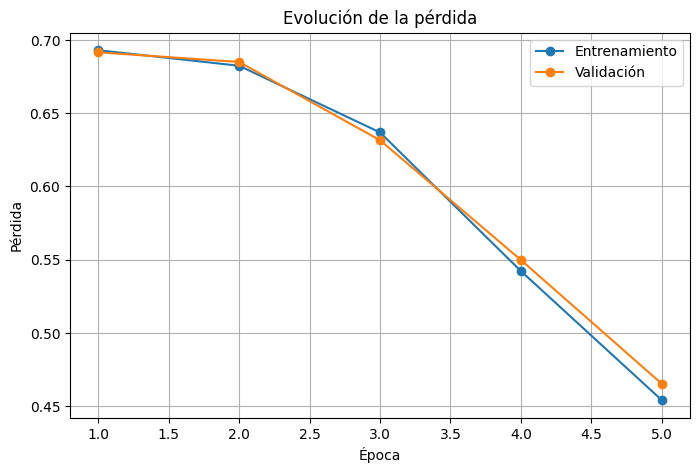

In [71]:
#Evolución de la pérdida
epocas = range(
    1,
    NUM_EPOCHS + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epocas,
    historial["train_loss"],
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    epocas,
    historial["val_loss"],
    marker="o",
    label="Validación"
)

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Evolución de la pérdida")
plt.legend()
plt.grid()
plt.show()

In [72]:
#Evaluación final sobre el conjunto de prueba
modelo.load_state_dict(
    torch.load(
        "mejor_modelo_lstm.pth",
        map_location=device
    )
)

<All keys matched successfully>

In [73]:
(
    test_loss,
    test_accuracy,
    etiquetas_reales,
    predicciones_test,
    probabilidades_test
) = evaluar_modelo(
    modelo,
    test_loader,
    criterio,
    device
)

print(f"Pérdida de prueba: {test_loss:.4f}")
print(f"Accuracy de prueba: {test_accuracy:.4f}")

Pérdida de prueba: 0.4673
Accuracy de prueba: 0.7954


In [74]:
#Informe de clasificación
print(
    classification_report(
        etiquetas_reales,
        predicciones_test,
        target_names=[
            "Negativo",
            "Positivo"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    Negativo     0.7472    0.8928    0.8136      2500
    Positivo     0.8669    0.6980    0.7733      2500

    accuracy                         0.7954      5000
   macro avg     0.8071    0.7954    0.7934      5000
weighted avg     0.8071    0.7954    0.7934      5000



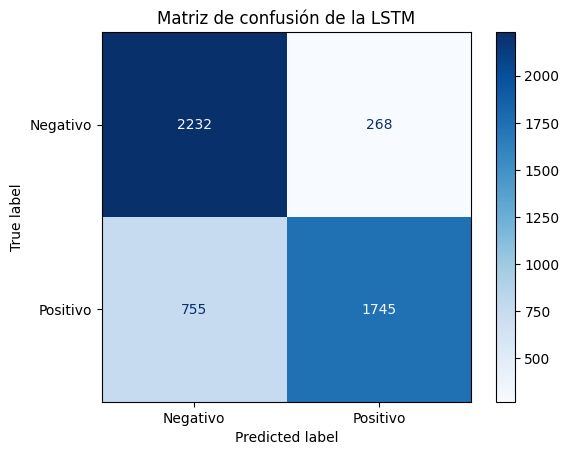

In [75]:
#Matriz de confusión
matriz_confusion = confusion_matrix(
    etiquetas_reales,
    predicciones_test
)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=[
        "Negativo",
        "Positivo"
    ]
)

visualizacion.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión de la LSTM")
plt.show()

El modelo LSTM obtuvo una accuracy del 79,54 %, lo que indica un rendimiento adecuado en la clasificación binaria de sentimientos. Se observa un mejor comportamiento al identificar las reseñas negativas (recall = 89,28 %) que las positivas (recall = 69,80 %). La matriz de confusión confirma este resultado, ya que clasifica correctamente 2232 reseñas negativas y 1745 positivas, aunque todavía confunde 755 reseñas positivas como negativas y 268 negativas como positivas. En conjunto, el modelo presenta una capacidad de clasificación satisfactoria, aunque existe margen de mejora en la detección de las reseñas positivas.

In [76]:
#Predicción de nuevas reseñas

def predecir_sentimiento(texto, modelo):
    modelo.eval()

    secuencia = texto_a_secuencia(texto)

    tensor_texto = torch.tensor(
        secuencia,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        logit = modelo(tensor_texto)

        probabilidad_positiva = torch.sigmoid(
            logit
        ).item()

    if probabilidad_positiva >= 0.5:
        sentimiento = "Positivo"
        confianza = probabilidad_positiva
    else:
        sentimiento = "Negativo"
        confianza = 1 - probabilidad_positiva

    return sentimiento, confianza

In [77]:
#probamos el modelo
reseñas_ejemplo = [
    "This movie was fantastic and the actors were excellent.",
    "The film was boring, predictable and a complete waste of time."
]

for reseña in reseñas_ejemplo:

    sentimiento, confianza = predecir_sentimiento(
        reseña,
        modelo
    )

    print("Reseña:", reseña)
    print("Sentimiento:", sentimiento)
    print(f"Confianza: {confianza:.4f}")
    print("-" * 70)

Reseña: This movie was fantastic and the actors were excellent.
Sentimiento: Positivo
Confianza: 0.8700
----------------------------------------------------------------------
Reseña: The film was boring, predictable and a complete waste of time.
Sentimiento: Negativo
Confianza: 0.8423
----------------------------------------------------------------------


En esta segunda parte se ha construido un clasificador binario de sentimientos mediante una red LSTM en PyTorch. Las reseñas del conjunto IMDB se limpiaron, tokenizaron y transformaron en secuencias numéricas a partir de un vocabulario creado con los datos de entrenamiento. El modelo empleó una capa de embeddings, una capa LSTM y una capa lineal para clasificar cada reseña como positiva o negativa. Finalmente, su rendimiento se evaluó mediante la exactitud, el informe de clasificación y la matriz de confusión, permitiendo comprobar su capacidad para distinguir los dos sentimientos considerados.